In [1]:
import sys
import torch
import torchvision
import numpy as np
import matplotlib
import sklearn

print("Python:", sys.version)
print("Python path:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: 3.11.17 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:16:54) [MSC v.1942 64 bit (AMD64)]
Python path: C:\Users\Admin\anaconda3\envs\fashion-mnist\python.exe
PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
NumPy: 2.4.6
Matplotlib: 3.11.2
Scikit-learn: 1.9.1


In [2]:
%pip install matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import torch
from torchvision import datasets

# Load the Fashion-MNIST training dataset
train_dataset = datasets.FashionMNIST(root="./data", train=True, download=True)

# Load the Fashion-MNIST test dataset
test_dataset = datasets.FashionMNIST(root="./data", train=False, download=True)

print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))
print("Number of classes:", len(train_dataset.classes))
print("Class names:", train_dataset.classes)

Training samples: 60000
Test samples: 10000
Number of classes: 10
Class names: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


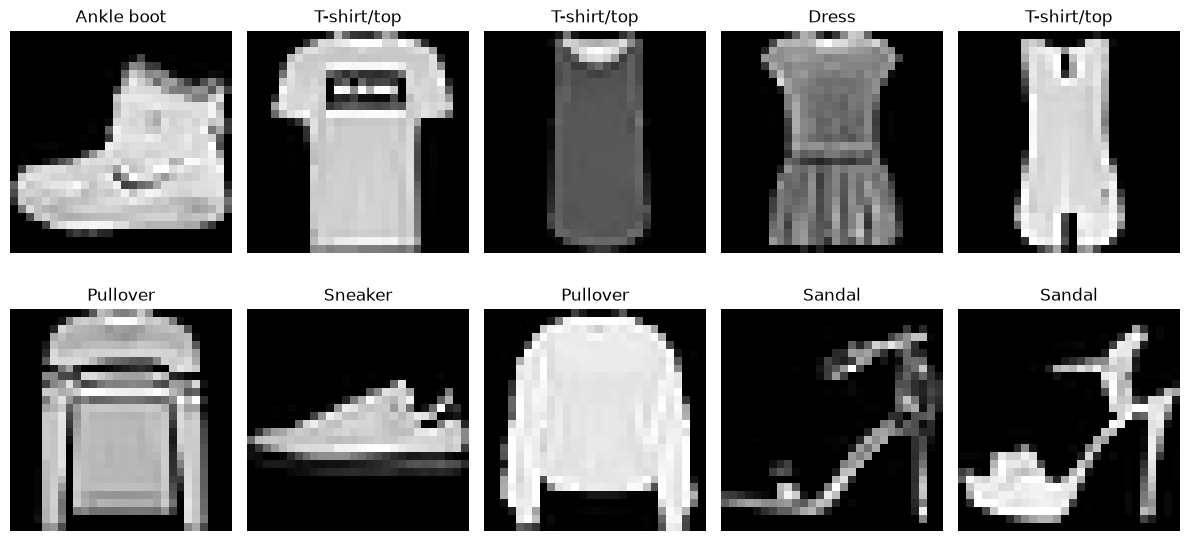

In [4]:
import matplotlib.pyplot as plt

# Display the first 10 images from the training dataset
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    ax.imshow(image, cmap="gray")
    ax.set_title(train_dataset.classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
image, label = train_dataset[0]

print("Image type:", type(image))
print("Image size:", image.size)
print("Label:", label)
print("Class name:", train_dataset.classes[label])

Image type: <class 'PIL.Image.Image'>
Image size: (28, 28)
Label: 9
Class name: Ankle boot


In [6]:
import numpy as np

image, label = train_dataset[0]

image_array = np.array(image)

print("Image shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())
print("First 5x5 pixels:\n", image_array[:5, :5])

Image shape: (28, 28)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
First 5x5 pixels:
 [[0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]


In [7]:
from torchvision import transforms

transform = transforms.ToTensor()

image, label = train_dataset[0]
image_tensor = transform(image)

print("Tensor shape:", image_tensor.shape)
print("Tensor data type:", image_tensor.dtype)
print("Minimum pixel value:", image_tensor.min().item())
print("Maximum pixel value:", image_tensor.max().item())
print("Label:", label)

Tensor shape: torch.Size([1, 28, 28])
Tensor data type: torch.float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Label: 9


In [8]:
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_dataset = datasets.FashionMNIST(root="./data", train=True, transform=transform, download=True)

test_dataset = datasets.FashionMNIST(root="./data", train=False, transform=transform, download=True)

image, label = train_dataset[0]

print("Image type:", type(image))
print("Image shape:", image.shape)
print("Image data type:", image.dtype)
print("Label:", label)
print("Class name:", train_dataset.classes[label])

Image type: <class 'torch.Tensor'>
Image shape: torch.Size([1, 28, 28])
Image data type: torch.float32
Label: 9
Class name: Ankle boot


In [9]:
from torch.utils.data import DataLoader

batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Batch size:", len(images))
print("First 10 labels:", labels[:10].tolist())

Images shape: torch.Size([32, 1, 28, 28])
Labels shape: torch.Size([32])
Batch size: 32
First 10 labels: [4, 0, 2, 3, 4, 6, 5, 6, 4, 8]


In [10]:
import torch
import torch.nn as nn

class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10))

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = FashionCNN()

print(model)

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [11]:
# Get one batch of images
images, labels = next(iter(train_loader))

# Pass the images through the feature extraction layers
x = images
print("Input shape:", x.shape)

x = model.features[0](x)
print("After Conv1:", x.shape)

x = model.features[1](x)
print("After ReLU1:", x.shape)

x = model.features[2](x)
print("After Pool1:", x.shape)

x = model.features[3](x)
print("After Conv2:", x.shape)

x = model.features[4](x)
print("After ReLU2:", x.shape)

x = model.features[5](x)
print("After Pool2:", x.shape)

# Pass through the classifier
x = model.classifier[0](x)
print("After Flatten:", x.shape)

x = model.classifier[1](x)
print("After Linear1:", x.shape)

x = model.classifier[2](x)
print("After ReLU3:", x.shape)

x = model.classifier[3](x)
print("Output shape:", x.shape)

Input shape: torch.Size([32, 1, 28, 28])
After Conv1: torch.Size([32, 32, 28, 28])
After ReLU1: torch.Size([32, 32, 28, 28])
After Pool1: torch.Size([32, 32, 14, 14])
After Conv2: torch.Size([32, 64, 14, 14])
After ReLU2: torch.Size([32, 64, 14, 14])
After Pool2: torch.Size([32, 64, 7, 7])
After Flatten: torch.Size([32, 3136])
After Linear1: torch.Size([32, 128])
After ReLU3: torch.Size([32, 128])
Output shape: torch.Size([32, 10])


In [12]:
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [13]:
from torch.utils.data import DataLoader, random_split

# Set a seed for reproducibility
generator = torch.Generator().manual_seed(42)

# Split the original training dataset
train_subset, val_subset = random_split(train_dataset, [54000, 6000], generator=generator)

# Create DataLoaders
train_loader = DataLoader(train_subset, batch_size=32, shuffle=True)

val_loader = DataLoader(val_subset, batch_size=32, shuffle=False)

test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Test samples:", len(test_dataset))

Training samples: 54000
Validation samples: 6000
Test samples: 10000


In [14]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [15]:
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [16]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("Using device:", device)

Using device: cpu


In [17]:
import time

num_epochs = 3

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(num_epochs):
    start_time = time.time()

    train_loss, train_accuracy = train_one_epoch(model, train_loader, criterion, optimizer, device)

    val_loss, val_accuracy = evaluate(model, val_loader, criterion, device)

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    elapsed_time = time.time() - start_time

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2%} | "
        f"Time: {elapsed_time:.1f}s"
    )

Epoch [1/3] | Train Loss: 0.4422 | Train Accuracy: 83.91% | Val Loss: 0.3388 | Val Accuracy: 88.02% | Time: 18.4s
Epoch [2/3] | Train Loss: 0.2814 | Train Accuracy: 89.68% | Val Loss: 0.2687 | Val Accuracy: 90.37% | Time: 17.8s
Epoch [3/3] | Train Loss: 0.2345 | Train Accuracy: 91.45% | Val Loss: 0.2593 | Val Accuracy: 90.67% | Time: 18.3s


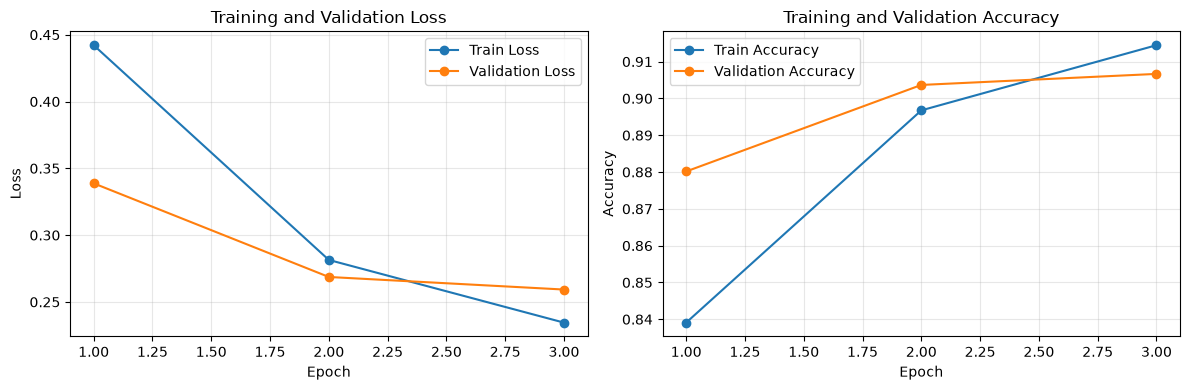

In [18]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss curves
axes[0].plot(epochs, history["train_loss"], marker="o", label="Train Loss")
axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy curves
axes[1].plot(epochs, history["train_accuracy"], marker="o", label="Train Accuracy")
axes[1].plot(epochs, history["val_accuracy"], marker="o", label="Validation Accuracy")
axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
additional_epochs = 5

for _ in range(additional_epochs):
    epoch = len(history["train_loss"]) + 1
    start_time = time.time()

    train_loss, train_accuracy = train_one_epoch(model, train_loader, criterion, optimizer, device)

    val_loss, val_accuracy = evaluate(model, val_loader, criterion, device)

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    elapsed_time = time.time() - start_time

    print(
        f"Epoch [{epoch}/8] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2%} | "
        f"Time: {elapsed_time:.1f}s"
    )

Epoch [4/8] | Train Loss: 0.2015 | Train Accuracy: 92.60% | Val Loss: 0.2412 | Val Accuracy: 91.10% | Time: 19.2s
Epoch [5/8] | Train Loss: 0.1758 | Train Accuracy: 93.33% | Val Loss: 0.2224 | Val Accuracy: 91.95% | Time: 18.0s
Epoch [6/8] | Train Loss: 0.1514 | Train Accuracy: 94.29% | Val Loss: 0.2344 | Val Accuracy: 92.07% | Time: 18.0s
Epoch [7/8] | Train Loss: 0.1303 | Train Accuracy: 95.06% | Val Loss: 0.2243 | Val Accuracy: 92.23% | Time: 18.2s
Epoch [8/8] | Train Loss: 0.1118 | Train Accuracy: 95.75% | Val Loss: 0.2371 | Val Accuracy: 92.35% | Time: 18.1s


In [20]:
import torch

torch.save(model.state_dict(), "fashion_cnn.pth")

print("Model saved successfully.")

Model saved successfully.


In [21]:
test_loss, test_accuracy = evaluate(model, test_loader, criterion, device)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

Test Loss: 0.2694
Test Accuracy: 91.73%


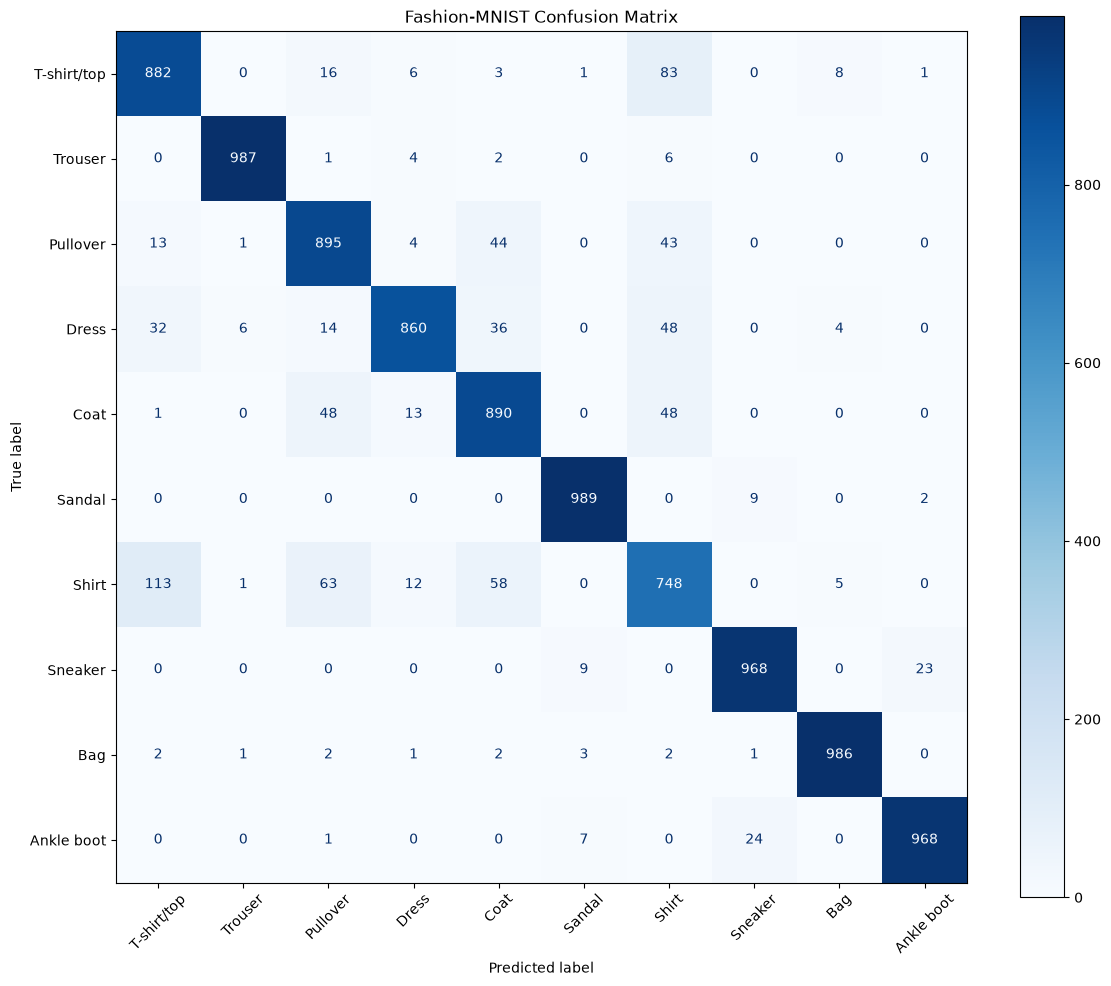

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_predictions, labels=list(range(10)))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=train_dataset.classes)

fig, ax = plt.subplots(figsize=(12, 10))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, values_format="d")
plt.title("Fashion-MNIST Confusion Matrix")
plt.tight_layout()
plt.show()

In [23]:
from sklearn.metrics import classification_report

report = classification_report(all_labels, all_predictions, target_names=train_dataset.classes, digits=4)

print(report)

              precision    recall  f1-score   support

 T-shirt/top     0.8456    0.8820    0.8634      1000
     Trouser     0.9910    0.9870    0.9890      1000
    Pullover     0.8606    0.8950    0.8775      1000
       Dress     0.9556    0.8600    0.9053      1000
        Coat     0.8599    0.8900    0.8747      1000
      Sandal     0.9802    0.9890    0.9846      1000
       Shirt     0.7648    0.7480    0.7563      1000
     Sneaker     0.9661    0.9680    0.9670      1000
         Bag     0.9831    0.9860    0.9845      1000
  Ankle boot     0.9738    0.9680    0.9709      1000

    accuracy                         0.9173     10000
   macro avg     0.9181    0.9173    0.9173     10000
weighted avg     0.9181    0.9173    0.9173     10000



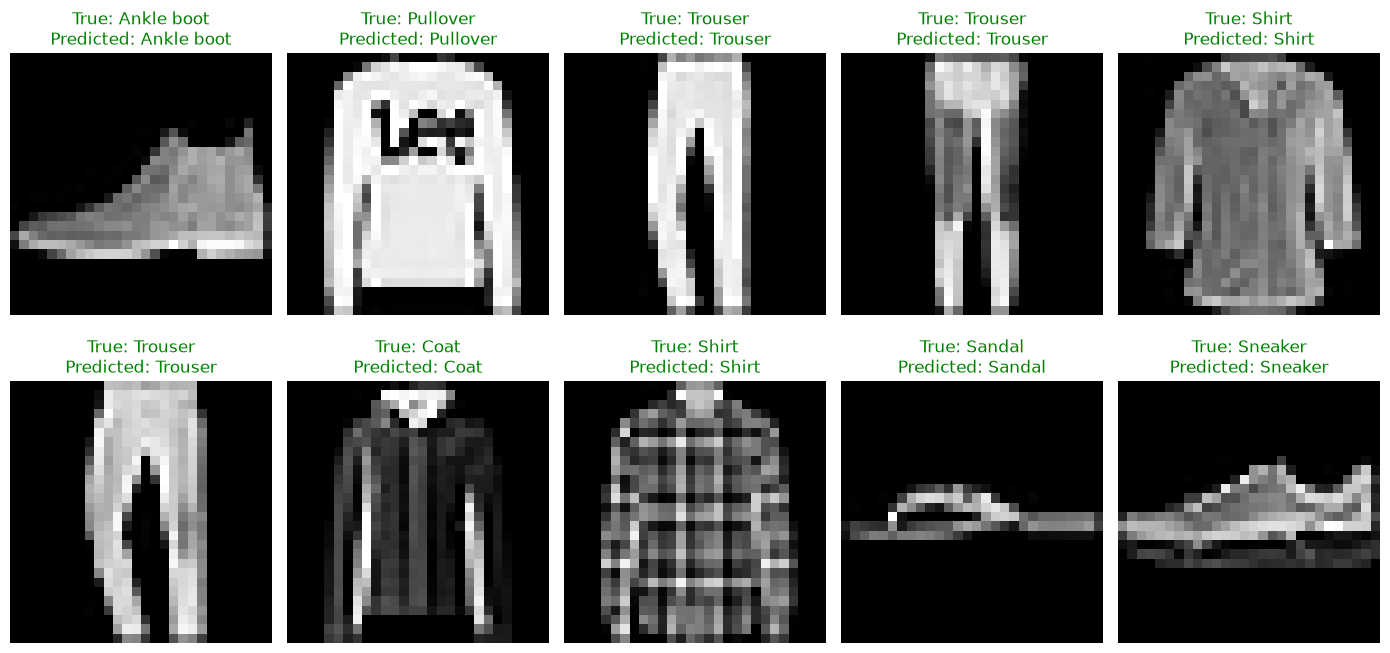

In [24]:
import matplotlib.pyplot as plt

model.eval()

images, labels = next(iter(test_loader))
images = images.to(device)

with torch.no_grad():
    outputs = model(images)
    predictions = outputs.argmax(dim=1).cpu()

images = images.cpu()

class_names = test_dataset.classes

fig, axes = plt.subplots(2, 5, figsize=(14, 7))

for i, ax in enumerate(axes.flat):
    image = images[i].squeeze(0)
    true_label = labels[i].item()
    predicted_label = predictions[i].item()

    ax.imshow(image, cmap="gray")
    ax.set_title(
        f"True: {class_names[true_label]}\n"
        f"Predicted: {class_names[predicted_label]}",
        color="green" if true_label == predicted_label else "red")
    ax.axis("off")

plt.tight_layout()
plt.show()

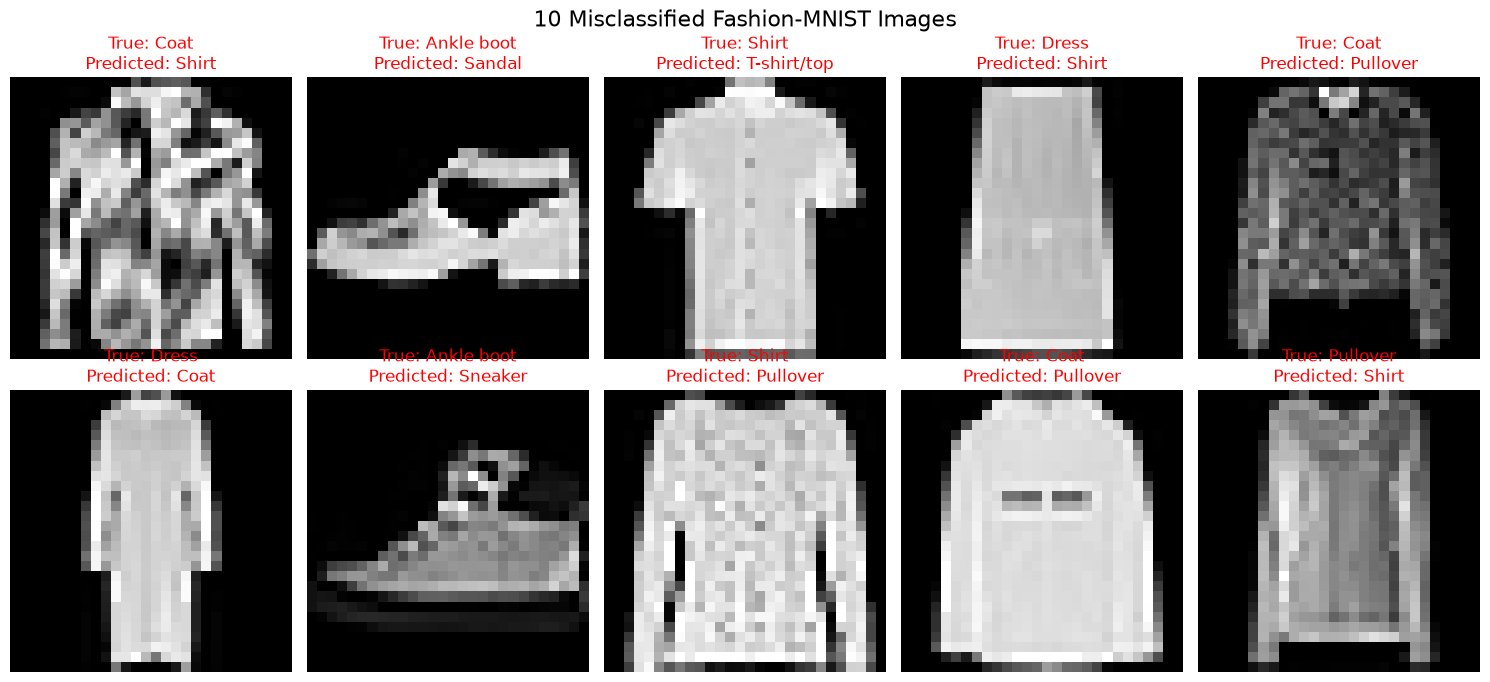

In [25]:
import matplotlib.pyplot as plt
import torch

model.eval()

misclassified_images = []
misclassified_labels = []
misclassified_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu()

        wrong_indices = (predictions != labels).nonzero(as_tuple=True)[0]

        for idx in wrong_indices:
            misclassified_images.append(images[idx].cpu())
            misclassified_labels.append(labels[idx].item())
            misclassified_predictions.append(predictions[idx].item())

            if len(misclassified_images) == 10:
                break

        if len(misclassified_images) == 10:
            break

class_names = test_dataset.classes

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for i, ax in enumerate(axes.flat):
    image = misclassified_images[i].squeeze(0)

    true_label = misclassified_labels[i]
    predicted_label = misclassified_predictions[i]

    ax.imshow(image, cmap="gray")
    ax.set_title(
        f"True: {class_names[true_label]}\n"
        f"Predicted: {class_names[predicted_label]}",
        color="red")
    ax.axis("off")

plt.suptitle("10 Misclassified Fashion-MNIST Images", fontsize=16)
plt.tight_layout()
plt.show()